In [1]:
import requests

url = "https://apps.fs.usda.gov/ArcX/rest/services/EDW/EDW_InsectandDiseaseSurvey_01/MapServer/1/query"
params = {
    "where": "SURVEY_YEAR >= 2012 AND SURVEY_YEAR <= 2016",
    "geometry": "-119.5,35.5,-118.5,37.5",
    "geometryType": "esriGeometryEnvelope",
    "inSR": "4326",
    "spatialRel": "esriSpatialRelIntersects",
    "outFields": "*",
    "returnGeometry": "true",
    "f": "geojson",
}
r = requests.get(url, params=params)
print(r.status_code)
data = r.json()
print(list(data.get("features", [{}])[0].get("properties", {}).keys()) if data.get("features") else data)


200
{'type': 'FeatureCollection', 'features': []}


In [2]:
import requests

layer_info = requests.get(
    "https://apps.fs.usda.gov/ArcX/rest/services/EDW/EDW_InsectandDiseaseSurvey_01/MapServer/1",
    params={"f": "json"},
).json()

print([f["name"] for f in layer_info.get("fields", [])])


['objectid', 'damage_area_id', 'created_date', 'modified_date', 'feature_user_id', 'observation_user_id', 'region_id', 'label', 'host_code', 'host', 'host_group_code', 'host_group', 'dca_code', 'dca_common_name', 'damage_type_code', 'damage_type', 'percent_affected_code', 'percent_affected', 'percent_min', 'percent_max', 'percent_mid', 'notes', 'observation_count', 'collection_mode', 'snapgrid_row', 'snapgrid_column', 'area_type', 'acres', 'status', 'survey_year', 'legacy_severity_code', 'legacy_severity', 'legacy_pattern_code', 'legacy_pattern', 'legacy_tpa', 'legacy_no_trees', 'legacy_forest_type_code', 'legacy_forest_type', 'grp', 'observation_id', 'ids_data_source', 'data_source_name', 'us_area', 'shape', 'st_area(shape)', 'st_perimeter(shape)']


In [5]:
params = {
    "where": "1=1",
    "outFields": "survey_year",
    "returnGeometry": "false",
    "returnDistinctValues": "true",
    "f": "json",
}
r = requests.get(url, params=params)
data = r.json()
years = sorted(set(f["attributes"]["survey_year"] for f in data.get("features", [])))
print(years)


[2021, 2022, 2023, 2024, 2025]


In [2]:
import requests

features = []
offset = 0
page_size = 2000
url = "https://services2.arcgis.com/Uq9r85Potqm3MfRV/ArcGIS/rest/services/biosds2783_fpu/FeatureServer/0/query"

while True:
    params = {
        "where": "RPT_YR >= 2012 AND RPT_YR <= 2016",
        "geometry": "-119.5,35.5,-118.5,37.5",
        "geometryType": "esriGeometryEnvelope",
        "inSR": "4326",
        "spatialRel": "esriSpatialRelIntersects",
        "outFields": "*",
        "f": "geojson",
        "resultRecordCount": page_size,
        "resultOffset": offset,
    }
    r = requests.get(url, params=params)
    batch = r.json().get("features", [])
    features.extend(batch)
    if len(batch) < page_size:
        break
    offset += page_size

print(len(features))
print(features[0]["properties"] if features else "no features")


9916
{'OBJECTID': 154299, 'RPT_YR': 2012, 'SURVEY_ID1': 'FHP', 'SURVEY_ID2': '-1', 'SURVEY_ID3': '-1', 'DMG_TYPE1': 'Mortality', 'DMG_TYPE2': 'No Data', 'DMG_TYPE3': 'No Data', 'SEVERITY1': 'No data', 'SEVERITY2': 'No data', 'SEVERITY3': 'No data', 'PATTERN1': None, 'PATTERN2': None, 'PATTERN3': None, 'TPA1': 1.43989100205, 'TPA2': -1, 'TPA3': -1, 'TPA_Total': 1.439891, 'NO_TREES1': 1, 'NO_TREES2': 0, 'NO_TREES3': 0, 'NO_TREES_TOTAL': 1, 'DCA1': 'western pine beetle', 'DCA2': 'No Data', 'DCA3': 'No Data', 'HOST1': 'ponderosa pine', 'HOST2': None, 'HOST3': None, 'FOR_TYPE1': 'Ponderosa pine', 'FOR_TYPE2': None, 'FOR_TYPE3': None, 'ACRES': 0.6945000237707799, 'NOTES': '1!pp', 'no_years': 1, 'Date': None, 'ADS_ID': None, 'Shape__Length0': None, 'Shape__Area0': None, 'Shape__Area': 4425.82421875, 'Shape__Length': 236.08801287078455}


In [3]:
from collections import Counter
print(Counter(f["properties"].get("DCA1") for f in features).most_common(15))


[('western pine beetle', 3027), ('mountain pine beetle', 2513), ('fir engraver', 1785), ('drought', 1103), ('Jeffery pine beetle', 924), ('California flathead borer', 142), ('Multi-Damage (Insect/Disease)', 117), ('Cytospora canker of fir', 70), ('Unknown', 69), ('Bark Beetles', 64), ('winter injury', 48), ('Fire', 31), ('Ips engraver beetles', 11), ('pinon ips', 6), ('satin moth', 2)]


In [5]:
import geopandas as gpd
from shapely.geometry import shape

TPA_CAP = 80.0  # UC Cooperative Extension: 20-80 dead trees/acre in severe Sierra mortality areas

def compute_severity_weight(p):
    tpa = p.get("TPA_Total")
    if tpa is None:
        acres = p.get("ACRES")
        trees = p.get("NO_TREES_TOTAL")
        if acres and trees and acres > 0:
            tpa = trees / acres
        else:
            tpa = 0.0
    return min(max(tpa, 0), TPA_CAP) / TPA_CAP

rows = []
for f in features:
    p = f["properties"]
    rows.append({
        "geometry": shape(f["geometry"]),
        "RPT_YR": p["RPT_YR"],
        "ACRES": p["ACRES"],
        "TPA_Total": p["TPA_Total"],
        "severity_weight": compute_severity_weight(p),
    })

ads_gdf = gpd.GeoDataFrame(rows, crs="EPSG:4326")
ads_gdf["damaged_acres"] = ads_gdf["ACRES"] * ads_gdf["severity_weight"]
print(len(ads_gdf), ads_gdf["damaged_acres"].sum())
print(ads_gdf["TPA_Total"].isna().sum(), "features had missing TPA_Total")


9916 543052.0314060146
191 features had missing TPA_Total


In [7]:
rows = []
for f in features:
    p = f["properties"]
    rows.append({
        "geometry": shape(f["geometry"]),
        "RPT_YR": p["RPT_YR"],
        "ACRES": p["ACRES"],
        "TPA_Total": p["TPA_Total"],
        "HOST1": p.get("HOST1"),
        "FOR_TYPE1": p.get("FOR_TYPE1"),
        "severity_weight": compute_severity_weight(p),
    })

ads_gdf = gpd.GeoDataFrame(rows, crs="EPSG:4326")
ads_gdf["damaged_acres"] = ads_gdf["ACRES"] * ads_gdf["severity_weight"]

print(ads_gdf["HOST1"].value_counts())


HOST1
ponderosa pine           2686
Jeffrey pine              930
lodgepole pine            789
sugar pine                709
white fir                 688
California red fir        597
blue oak                  430
whitebark pine            320
fir                       219
interior live oak         163
western white pine         81
softwoods *                33
oak(deciduous)             24
canyon live oak            19
grey pine                  16
limber pine                16
California black oak       16
pine                       13
hardwoods/softwoods *      12
hardwoods *                10
quaking aspen               6
singleleaf pinyon           5
bigleaf maple               3
cottonwood, poplar          2
not listed                  2
knobcone pine               2
incense-cedar               2
eucalyptus                  1
foxtail pine                1
willow                      1
California sycamore         1
Name: count, dtype: int64


In [10]:
import xarray as xr
import numpy as np

spei_ds = xr.open_dataset("../data/raw/spei12.nc")
lats = spei_ds["lat"].values
lons = spei_ds["lon"].values

# SPEI cells whose centers fall in/near the pilot bbox
bbox = dict(lon=slice(-119.5, -118.5), lat=slice(35.5, 37.5))
pilot_lats = spei_ds.sel(**bbox)["lat"].values
pilot_lons = spei_ds.sel(**bbox)["lon"].values
print(pilot_lats, pilot_lons)  # check how many cells we actually have to work with

def nearest_cell(lon, lat):
    lat_i = pilot_lats[np.argmin(np.abs(pilot_lats - lat))]
    lon_i = pilot_lons[np.argmin(np.abs(pilot_lons - lon))]
    return (lat_i, lon_i)

ads_proj = ads_gdf.to_crs(3310)
centroids_latlon = ads_proj.centroid.to_crs(4326)

ads_gdf["cell"] = [
    nearest_cell(pt.x, pt.y) for pt in centroids_latlon
]
damaged_by_cell = ads_gdf.groupby("cell")["damaged_acres"].sum()
print(damaged_by_cell)


[35.75 36.25 36.75 37.25] [-119.25 -118.75]
cell
(35.75, -119.25)         0.312500
(35.75, -118.75)     77372.902371
(36.25, -119.25)        10.070879
(36.25, -118.75)    119043.467886
(36.75, -119.25)     44842.682255
(36.75, -118.75)     80968.158974
(37.25, -119.25)    217841.254377
(37.25, -118.75)      2973.182165
Name: damaged_acres, dtype: float64


In [12]:
import ee
ee.Authenticate()
ee.Initialize(project="tree-fire-510209")


Enter verification code:  4/1AUn6Hd_B8NArYTcpSNWGIR6Ksj-XCplNPP7Vj1_Ig04AGVJNXJgXfYLfvdc



Successfully saved authorization token.


In [17]:
import ee
import pandas as pd
ee.Initialize()

nlcd = ee.ImageCollection("USGS/NLCD_RELEASES/2016_REL").filter(ee.Filter.eq("system:index", "2016")).first()
forest_mask = nlcd.select("landcover").remap([41, 42, 43], [1, 1, 1], 0)
pixel_area_acres = ee.Image.pixelArea().divide(4046.8564224)
forested_acres_img = forest_mask.multiply(pixel_area_acres).rename("forested_acres")

forested_by_cell = {}
for lat, lon in damaged_by_cell.index:
    geom = ee.Geometry.Rectangle([lon - 0.25, lat - 0.25, lon + 0.25, lat + 0.25])
    val = forested_acres_img.reduceRegion(ee.Reducer.sum(), geom, scale=30, maxPixels=1e9).get("forested_acres")
    forested_by_cell[(lat, lon)] = val.getInfo()

forested_by_cell = pd.Series(forested_by_cell)
print(forested_by_cell)


35.75  -119.25         0.000000
       -118.75    123851.546960
36.25  -119.25       103.901127
       -118.75    274671.031010
36.75  -119.25    123273.302924
       -118.75    304203.119595
37.25  -119.25    422221.289933
       -118.75    143857.351558
dtype: float64


In [18]:
loss_share = damaged_by_cell / forested_by_cell
loss_share = loss_share.where(forested_by_cell > 0)  # avoid div-by-zero; NaN for near-empty cells
loss_share = loss_share.clip(0, 1)
print(loss_share.sort_values(ascending=False))


cell
(35.75, -118.75)    0.624723
(37.25, -119.25)    0.515941
(36.25, -118.75)    0.433404
(36.75, -119.25)    0.363766
(36.75, -118.75)    0.266165
(36.25, -119.25)    0.096928
(37.25, -118.75)    0.020668
(35.75, -119.25)         NaN
dtype: float64


In [19]:
spei_by_cell = {}
for lat, lon in loss_share.index:
    val = (
        spei_ds["spei"]
        .sel(lat=lat, lon=lon, method="nearest")
        .sel(time=slice("2012-01-01", "2016-12-31"))
        .mean()
    )
    spei_by_cell[(lat, lon)] = float(val)

spei_by_cell = pd.Series(spei_by_cell)

curve_df = pd.DataFrame({"loss_share": loss_share, "spei": spei_by_cell}).dropna()
print(curve_df.sort_values("spei"))


                  loss_share      spei
(36.25, -119.25)    0.096928 -0.957353
(36.25, -118.75)    0.433404 -0.856199
(36.75, -118.75)    0.266165 -0.792466
(37.25, -119.25)    0.515941 -0.722372
(37.25, -118.75)    0.020668 -0.701279
(36.75, -119.25)    0.363766 -0.636741
(35.75, -118.75)    0.624723 -0.452709


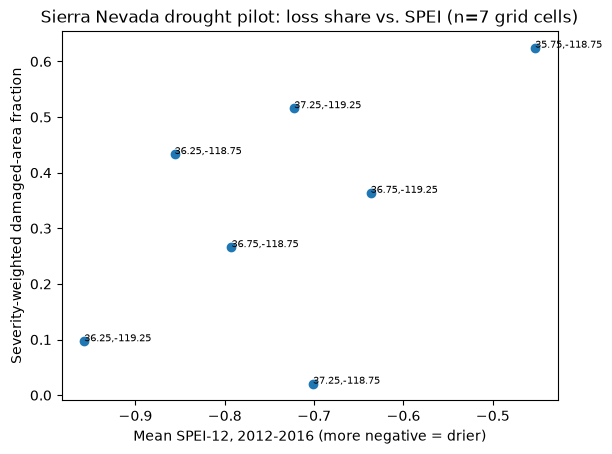

In [20]:
import matplotlib.pyplot as plt

plt.scatter(curve_df["spei"], curve_df["loss_share"])
for (lat, lon), row in curve_df.iterrows():
    plt.annotate(f"{lat},{lon}", (row["spei"], row["loss_share"]), fontsize=7)
plt.xlabel("Mean SPEI-12, 2012-2016 (more negative = drier)")
plt.ylabel("Severity-weighted damaged-area fraction")
plt.title("Sierra Nevada drought pilot: loss share vs. SPEI (n=7 grid cells)")
plt.savefig("../data/raw/drought_loss_vs_spei.png")
plt.show()


In [21]:
cell_a = ads_gdf[ads_gdf["cell"] == (37.25, -119.25)]  # loss_share 0.52
cell_b = ads_gdf[ads_gdf["cell"] == (37.25, -118.75)]  # loss_share 0.02

print("=== (37.25, -119.25), high loss share ===")
print(cell_a["HOST1"].value_counts())
print("damaged acres by species:")
print(cell_a.groupby("HOST1")["damaged_acres"].sum().sort_values(ascending=False))

print("\n=== (37.25, -118.75), low loss share ===")
print(cell_b["HOST1"].value_counts())
print("damaged acres by species:")
print(cell_b.groupby("HOST1")["damaged_acres"].sum().sort_values(ascending=False))


=== (37.25, -119.25), high loss share ===
HOST1
ponderosa pine           1060
lodgepole pine            276
Jeffrey pine              238
white fir                 221
California red fir        154
sugar pine                129
fir                        80
whitebark pine             26
western white pine         25
blue oak                   12
interior live oak          12
pine                        3
hardwoods/softwoods *       2
grey pine                   2
oak(deciduous)              2
softwoods *                 1
Name: count, dtype: int64
damaged acres by species:
HOST1
ponderosa pine           107100.291697
white fir                 59368.860591
fir                       19238.327947
Jeffrey pine              15383.338718
California red fir        10471.111450
lodgepole pine             4922.766410
sugar pine                  318.188585
interior live oak           191.840189
blue oak                    151.584249
whitebark pine               68.749993
oak(deciduous)          

In [22]:
rows = []
for f in features:
    p = f["properties"]
    rows.append({
        "geometry": shape(f["geometry"]),
        "RPT_YR": p["RPT_YR"],
        "ACRES": p["ACRES"],
        "TPA_Total": p["TPA_Total"],
        "NO_TREES_TOTAL": p.get("NO_TREES_TOTAL"),
        "HOST1": p.get("HOST1"),
        "FOR_TYPE1": p.get("FOR_TYPE1"),
        "severity_weight": compute_severity_weight(p),
    })

ads_gdf = gpd.GeoDataFrame(rows, crs="EPSG:4326")
ads_gdf["damaged_acres"] = ads_gdf["ACRES"] * ads_gdf["severity_weight"]
ads_proj = ads_gdf.to_crs(3310)
centroids_latlon = ads_proj.centroid.to_crs(4326)
ads_gdf["cell"] = [nearest_cell(pt.x, pt.y) for pt in centroids_latlon]


In [23]:
ponderosa = ads_gdf[ads_gdf["HOST1"] == "ponderosa pine"]

ponderosa_by_cell = ponderosa.groupby("cell").agg(
    mean_tpa=("TPA_Total", "mean"),
    total_dead_trees=("NO_TREES_TOTAL", "sum"),
    total_damaged_acres=("damaged_acres", "sum"),
    n_polygons=("TPA_Total", "count"),
)
print(ponderosa_by_cell)


                   mean_tpa  total_dead_trees  total_damaged_acres  n_polygons
cell                                                                          
(35.75, -118.75)  23.257823           5285135         65343.741997         458
(36.25, -118.75)  21.981725           4072746         50378.525765         566
(36.75, -119.25)  24.730397           2154608         26562.369452         229
(36.75, -118.75)  26.348616           3247254         39457.549145         372
(37.25, -119.25)  25.935216           8614835        107100.291697        1060
(37.25, -118.75)   6.380949                10             0.125000           1
